# Neural ODEs for Dynamic Surrogate Modeling
**Blaine Swieder · CS 8395-04**

**R5: Full Silverbox rollouts and residuals.** Extract the complete ZIP, open this
notebook in that folder, select `myenv_3`, and restart the kernel before Run All.

The model, dataset, and training settings follow the preceding notebook. The
response figures now show every forecast sample and a separate residual panel.
Fresh training runs in an isolated CPU worker with progress and a 90 s deadline.
Packaged reference results have a separate label if fresh execution fails.


In [1]:
import os,sys,time,json,csv,math,tempfile,subprocess,hashlib
from pathlib import Path
from IPython.display import Image,Markdown,Code,display

NOTEBOOK_REVISION='R5-2026-10-15-Silverbox-Residuals'
RUN_LIVE_DEMO=True
LIVE_TIMEOUT_SECONDS=90
ROOT=Path.cwd().resolve()
assert (ROOT/'silverbox_demo.py').is_file(), 'Extract the ZIP and open the notebook beside silverbox_demo.py.'
CONFIG=json.loads((ROOT/'config.json').read_text())
RESULTS=ROOT/'results'
print('NOTEBOOK REVISION:',NOTEBOOK_REVISION)
print('Interpreter:',sys.executable)
print('Python:',sys.version.split()[0])
print('The worker reports actual imported scientific-module versions.')
print('Fresh training:',RUN_LIVE_DEMO,'| worker limit:',LIVE_TIMEOUT_SECONDS,'s')
print('Updates per model:',CONFIG['updates'],'| seed:',CONFIG['seed'])

def digest(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def table(headers,rows):
    lines=['| '+' | '.join(map(str,headers))+' |','| '+' | '.join(['---']*len(headers))+' |']
    lines.extend('| '+' | '.join(map(str,row))+' |'for row in rows)
    display(Markdown('\n'.join(lines)))
def show(name):display(Image(filename=str(active_results/name)))

NOTEBOOK REVISION: R5-2026-10-15-Silverbox-Residuals
Interpreter: /workspace/scratch/acf5d2f58510/.neural-ode-venv/bin/python
Python: 3.12.14
The worker reports actual imported scientific-module versions.
Fresh training: True | worker limit: 90 s
Updates per model: 120 | seed: 17


## 1. Physical System and Measured Dataset

Silverbox is an electronic implementation of a nonlinear Duffing-like oscillator.
Its measured input is voltage $u(t)$ and its measured response is voltage $y(t)$.
These values are **volts**, not mechanical displacement or velocity.

- Source: [Silverbox benchmark](https://www.nonlinearbenchmark.org/benchmarks/silverbox).
- Original record: `SNLS80mV.mat`. Sampling frequency: 610.35 Hz.
- Four contiguous classroom subsets remain inside the official data partitions.
- Normalization and the linear warm start use training data only.
- Each evaluation clip allows 50 output samples for initialization, then uses
  the measured input alone. We score the remaining 1,998 samples.
- These short clips do not constitute the full Silverbox benchmark protocol.


In [2]:
manifest=json.loads((ROOT/'data/source_manifest.json').read_text())
rows=[]
for split,record in manifest['classroom_subsets'].items():
    path=ROOT/'data'/record['file']
    assert digest(path)==record['sha256'], 'Data checksum mismatch: '+path.name
    with path.open(newline='')as stream:sample=list(csv.DictReader(stream))
    assert len(sample)==record['rows']
    rows.append((split,len(sample),record['raw_start_inclusive'],record['raw_stop_exclusive']))
table(['Split','Rows','Source index start','Stop (excluded)'],rows)
with (ROOT/'data/silverbox_train.csv').open(newline='')as stream:
    reader=csv.DictReader(stream);preview=[next(reader)for _ in range(5)]
table(list(preview[0]),[list(row.values())for row in preview])
print('CSV values and SHA-256 checksums verified.')

CSV values and SHA-256 checksums verified.


| Split | Rows | Source index start | Stop (excluded) |
| --- | --- | --- | --- |
| train | 8192 | 40986 | 49178 |
| validation | 2048 | 58370 | 60418 |
| test | 2048 | 105712 | 107760 |
| high_amplitude | 2048 | 35000 | 37048 |

| sample_index | time_s | input_voltage_V | output_voltage_V |
| --- | --- | --- | --- |
| 40986 | 67.15163430818383 | 0.0030593738734372893 | 0.036534139689971927 |
| 40987 | 67.15327271237814 | -0.0075005326277751009 | 0.007582397943950491 |
| 40988 | 67.15491111657245 | -0.016508726158074569 | -0.028888980199181243 |
| 40989 | 67.156549520766774 | -0.0091363294725597365 | -0.059074046639184231 |
| 40990 | 67.158187924961084 | 0.012309291351324646 | -0.065955376590829104 |

**Measured Silverbox Training Input and Output**

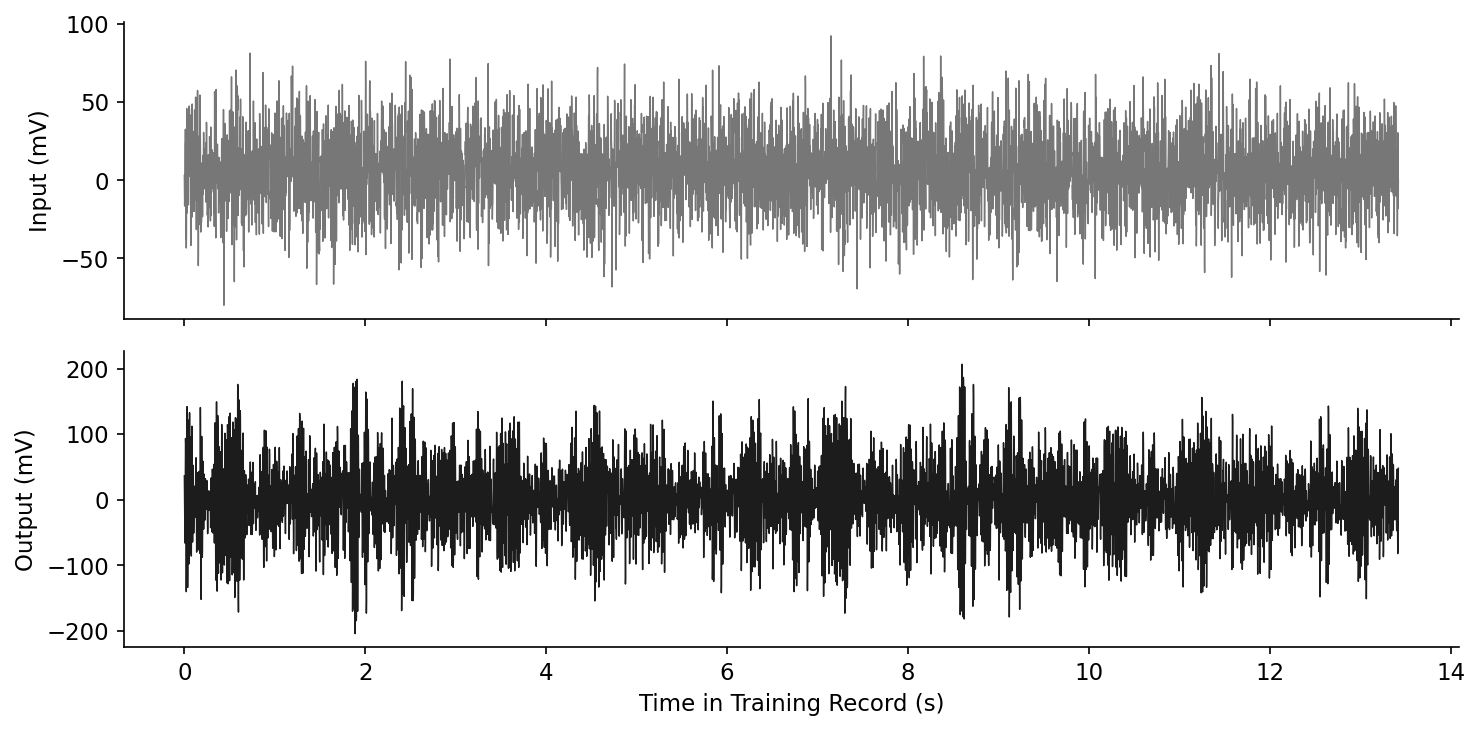

In [3]:
display(Markdown('**Measured Silverbox Training Input and Output**'))
display(Image(filename=str(RESULTS/'training_data.png')))

## 2. Learned Equation and Solver

Time in the solver is $\tau=(t-t_0)/\Delta t$, where $\Delta t=1/610.35$ s.

$$\frac{d z}{d\tau}=Az+Bu(\tau)+g_\theta([z,u(\tau)]),\qquad
  \widehat y=\mu_y+\sigma_y z_1.$$

- $u$ and $y$ use training-set centering and scaling.
- Two latent coordinates initialize from the last two outputs in the prefix.
  After initialization, the second coordinate is a learned memory variable.
- The network learns a correction to a continuous linear warm start.
- The augmented comparison adds a third coordinate initialized at zero.
- Two tanh hidden layers of width 16. Ordinary model: 370 neural parameters.
  Augmented model: 403 neural parameters.
- `torchdiffeq.odeint` uses fixed-step RK4, half a sample interval per step.
- `silverbox_demo.py` contains the complete readable model, training, evaluation,
  and plotting code. The notebook uses the same file through a separate process.


In [4]:
source=(ROOT/'silverbox_demo.py').read_text()
start=source.index('class InputDrivenODE')
end=source.index('\ndef initial_state',start)
display(Code(source[start:end],language='python'))

class InputDrivenODE(nn.Module):
    """Two latent coordinates; augmentation optionally adds one zero-initialized coordinate."""
    def __init__(self,A,B,width=16,augmented=False,linear=False):
        super().__init__();self.dimension=3 if augmented else 2;self.linear=linear
        aa=torch.zeros(self.dimension,self.dimension);aa[:2,:2]=A
        bb=torch.zeros(self.dimension,1);bb[:2]=B
        self.register_buffer('A',aa);self.register_buffer('B',bb)
        if not linear:
            self.network=nn.Sequential(nn.Linear(self.dimension+1,width),nn.Tanh(),
                nn.Linear(width,width),nn.Tanh(),nn.Linear(width,self.dimension))
            with torch.no_grad():
                self.network[-1].weight.mul_(0.01);self.network[-1].bias.zero_()
        self.input_path=None
    def set_input(self,values):
        self.input_path=values if values.ndim==3 else values[:,None,None]
    def forward(self,t,state):
        # tau is time in sample intervals. Piecewise-linear input interpolation.
        i=max(0,min(int(t.detach()),len(self.input_path)-2));fraction=t-i
        u=self.input_path[i]+fraction*(self.input_path[i+1]-self.input_path[i])
        derivative=state@self.A.T+u@self.B.T
        if not self.linear:derivative=derivative+self.network(torch.cat((state,u),dim=-1))
        return derivative

In [5]:
def run_isolated(timeout_s):
    """Keep numerical work outside the notebook kernel, with progress and a deadline."""
    output=RESULTS/'live';output.mkdir(parents=True,exist_ok=True)
    log_path=RESULTS/'live_worker.log'
    environment=os.environ.copy()
    for name in ('OMP_NUM_THREADS','MKL_NUM_THREADS','OPENBLAS_NUM_THREADS'):
        environment[name]='1'
    process=None;seen=0;started=time.perf_counter();status='failed'
    try:
        with tempfile.TemporaryDirectory(prefix='silverbox_config_')as folder:
            config_path=Path(folder)/'config.json';config_path.write_text(json.dumps(CONFIG))
            with log_path.open('wb')as log:
                process=subprocess.Popen([sys.executable,'-u',str(ROOT/'silverbox_demo.py'),
                    '--config',str(config_path),'--output',str(output)],cwd=ROOT,env=environment,
                    stdin=subprocess.DEVNULL,stdout=log,stderr=subprocess.STDOUT)
                deadline=time.perf_counter()+timeout_s
                while process.poll()is None:
                    current=log_path.read_bytes()
                    if len(current)>seen:
                        print(current[seen:].decode('utf-8',errors='replace'),end='',flush=True);seen=len(current)
                    if time.perf_counter()>=deadline:
                        status='timed_out';process.kill();process.wait(timeout=5)
                        print('WORKER TIME LIMIT REACHED. Worker stopped.',flush=True);break
                    time.sleep(.2)
            tail=log_path.read_bytes()[seen:]
            if tail:print(tail.decode('utf-8',errors='replace'),end='',flush=True)
            if status!='timed_out'and process.returncode==0:status='succeeded'
    finally:
        if process is not None and process.poll()is None:
            process.kill();process.wait(timeout=5)
    return status,output,time.perf_counter()-started

## 3. Live Run

The default run fits both networks from scratch for 120 Adam updates each.
Each update uses 16 training windows, each 24 sample intervals long.
Validation chooses the checkpoint every 20 updates using the first 256 forecast
intervals in the validation clip. Test outputs never enter fitting or selection.

The worker fixes seed 17, uses one CPU thread and float64 arithmetic, and enables
deterministic PyTorch algorithms. The 90 s limit includes scientific imports,
training, forecasts, and plotting after the worker starts. `RUN_LIVE_DEMO=False`
uses the packaged reference results without retraining.


In [6]:
if RUN_LIVE_DEMO:
    status,live_directory,elapsed=run_isolated(LIVE_TIMEOUT_SECONDS)
else:
    status,live_directory,elapsed='disabled',None,0.0
if status=='succeeded':
    active_results=live_directory
    result_source='LIVE RESULTS: fresh training in the current environment'
else:
    active_results=RESULTS
    result_source='PACKAGED REFERENCE RESULTS: live status '+status
    print('Use results/live_worker.log and its last stage to diagnose a failure.')
metrics=json.loads((active_results/'metrics.json').read_text())
print('\n'+result_source)
print('Elapsed:',round(elapsed,2),'s')
print('Measured data source:',manifest['dataset'])
print('Result folder:',active_results)
print('Selected updates:',metrics['selected_updates'])

[   0.0 s] Importing NumPy, PyTorch, SciPy, and torchdiffeq
[   4.6 s] Loaded PyTorch 2.8.0+cpu, NumPy 2.3.5, SciPy 1.17.0
[   4.6 s] Reading and validating four Silverbox CSV files
[   4.8 s] Fitting Neural ODE from scratch
[   8.3 s] Neural ODE update 1/120, validation MSE 0.06259
[  10.9 s] Neural ODE update 20/120, validation MSE 0.03312
[  12.7 s] Neural ODE update 40/120, validation MSE 0.01410
[  14.2 s] Neural ODE update 60/120, validation MSE 0.00947
[  15.9 s] Neural ODE update 80/120, validation MSE 0.00757
[  17.5 s] Neural ODE update 100/120, validation MSE 0.01112
[  19.0 s] Neural ODE update 120/120, validation MSE 0.00543
[  19.0 s] Fitting augmented Neural ODE from scratch
[  19.3 s] Augmented ODE update 1/120, validation MSE 0.06200
[  20.7 s] Augmented ODE update 20/120, validation MSE 0.04036
[  22.7 s] Augmented ODE update 40/120, validation MSE 0.01960
[  26.0 s] Augmented ODE update 60/120, validation MSE 0.01454
[  28.9 s] Augmented ODE update 80/120, validation

## 4. Test Response and Classical Baseline

The linear baseline comes from a training-only second-order ARX fit, converted
into a continuous linear state-space model with a matrix logarithm. Both neural
models start from that linear vector field and learn a nonlinear correction.

$$\mathrm{RMSE}_{\mathrm{mV}}=1000\sqrt{\frac{1}{N}\sum_{i=1}^{N}(\widehat y_i-y_i)^2}.$$

We evaluate open-loop response after the initialization prefix. Future measured
outputs do not reset or correct the model. The input trajectory remains known.

The upper panel shows the full 3.27 s response: measured samples as gray points
and the model as a gold line. The lower panel shows signed residuals,
$e_i=1000(\widehat y_i-y_i)$ in mV, for all 1,998 scored forecast samples.
The initialized point is excluded from residuals and RMSE. Both test figures use
the same output and error scales. The complete residual reveals differences that
are difficult to distinguish in an overlapping response plot.


**LIVE RESULTS: fresh training in the current environment**

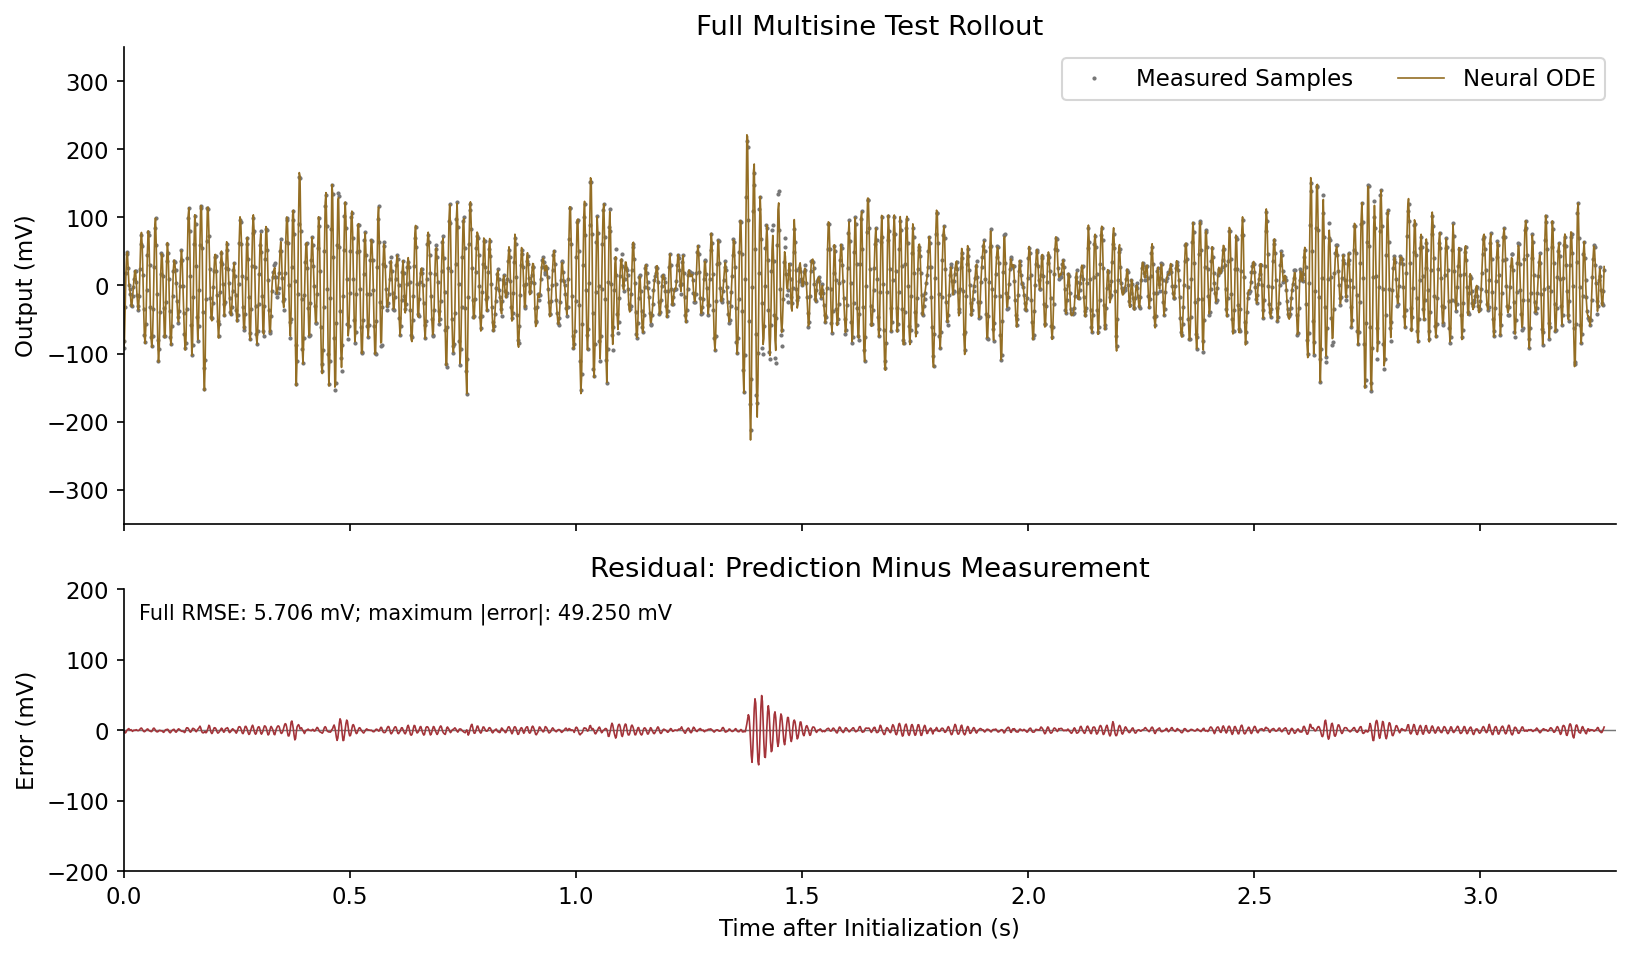

| Model | Test output RMSE (mV) | Test fit (%) |
| --- | --- | --- |
| Linear ODE | 18.060 | 67.90 |
| Neural ODE | 5.706 | 89.86 |
| Augmented Neural ODE | 4.435 | 92.12 |

In [7]:
display(Markdown('**'+result_source+'**'))
show('held_out.png')
table(['Model','Test output RMSE (mV)','Test fit (%)'],
      [(name,f"{value['test']['rmse_mV']:.3f}",f"{value['test']['fit_percent']:.2f}")
       for name,value in metrics['scores'].items()])

## 5. Changed Excitation and Generalization

The separate arrow-record clip contains larger output amplitudes than the
training clip and a different excitation waveform. This comparison does not
isolate amplitude as the cause of error. We repeat the same 50-sample local
initialization and input-only rollout within that clip.

The figure shows its entire 3.27 s response and residual, using the same scales
as the multisine test. The ordinary Neural ODE has larger errors across the full rollout.
The table scores all 1,998 forecast samples, including those larger errors.


**LIVE RESULTS: fresh training in the current environment**

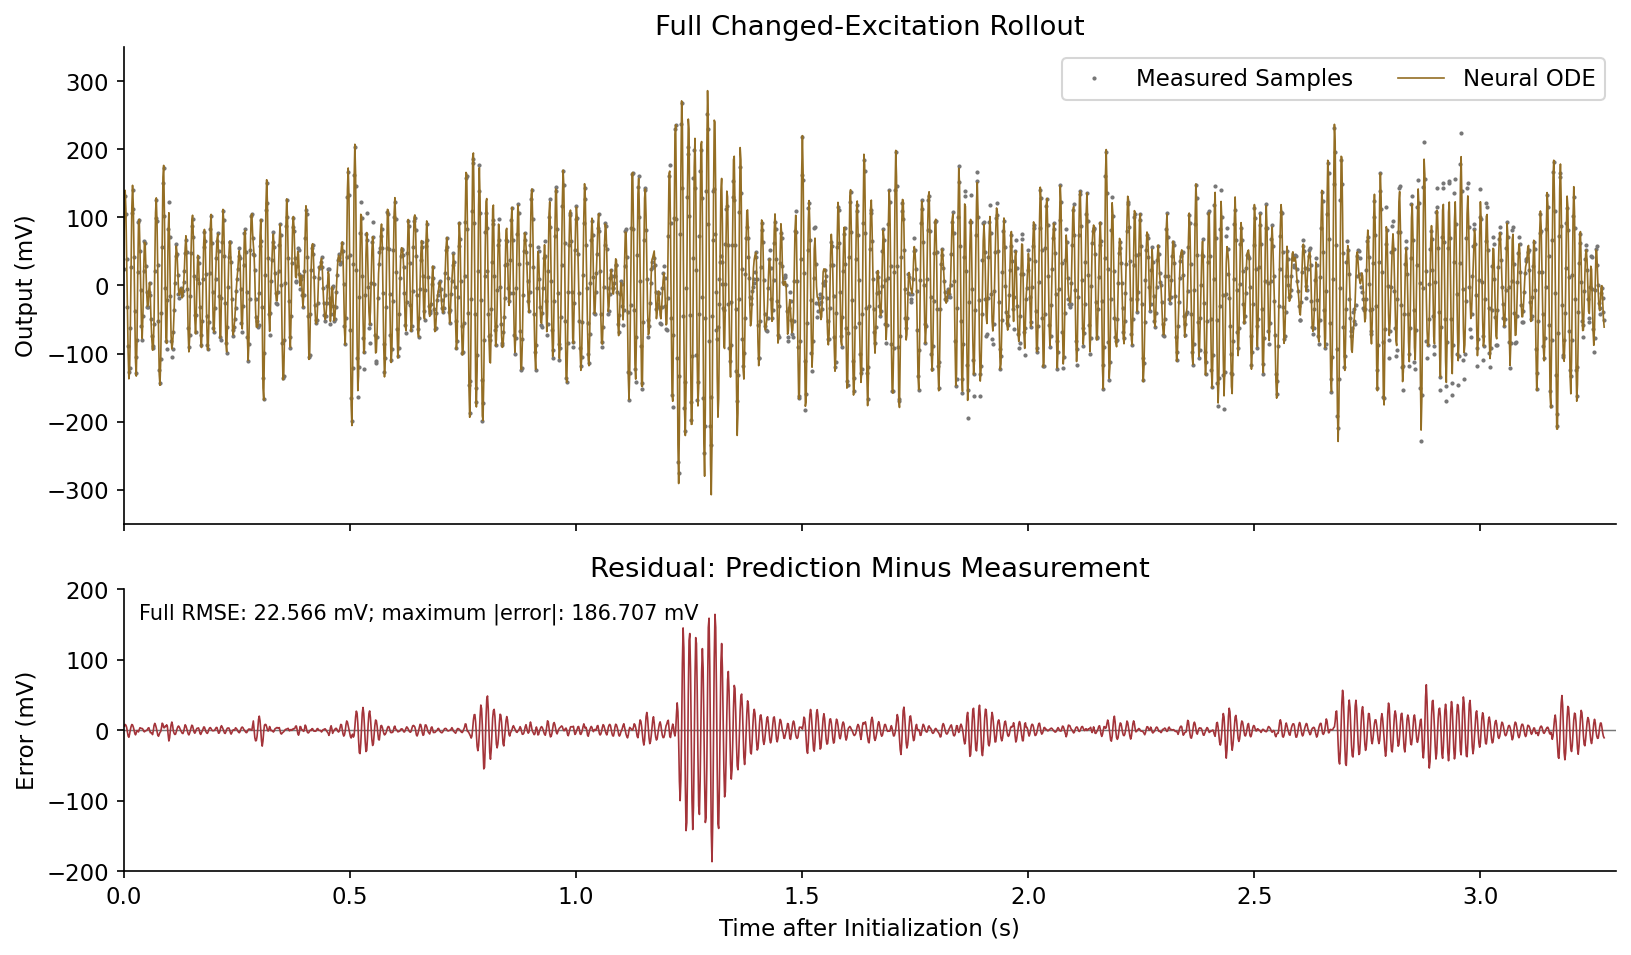

| Model | Multisine test RMSE (mV) | Larger-amplitude clip RMSE (mV) |
| --- | --- | --- |
| Linear ODE | 18.060 | 27.454 |
| Neural ODE | 5.706 | 22.566 |
| Augmented Neural ODE | 4.435 | 20.834 |

In [8]:
display(Markdown('**'+result_source+'**'))
show('amplitude_test.png')
table(['Model','Multisine test RMSE (mV)','Larger-amplitude clip RMSE (mV)'],
      [(name,f"{value['test']['rmse_mV']:.3f}",f"{value['high_amplitude']['rmse_mV']:.3f}")
       for name,value in metrics['scores'].items()])

## 6. Training Objective and Checkpoint History

$$\mathcal L(\theta)=\frac{1}{BN}\sum_{b=1}^{B}\sum_{i=1}^{N}
 \left(\frac{\widehat y^{(b)}_\theta(t_i)-y^{(b)}(t_i)}{\sigma_y}\right)^2.$$

$B=16$ windows and $N=25$ sampled points per window. Direct automatic
 differentiation through RK4 supplies gradients. This implementation uses
`odeint`, not `odeint_adjoint`; it does not reproduce the original paper's
continuous-adjoint memory claim.

Both models receive the same training-window sequence and update budget.
Their different parameter counts are reported, so the comparison is not an
exact parameter-matched ablation.


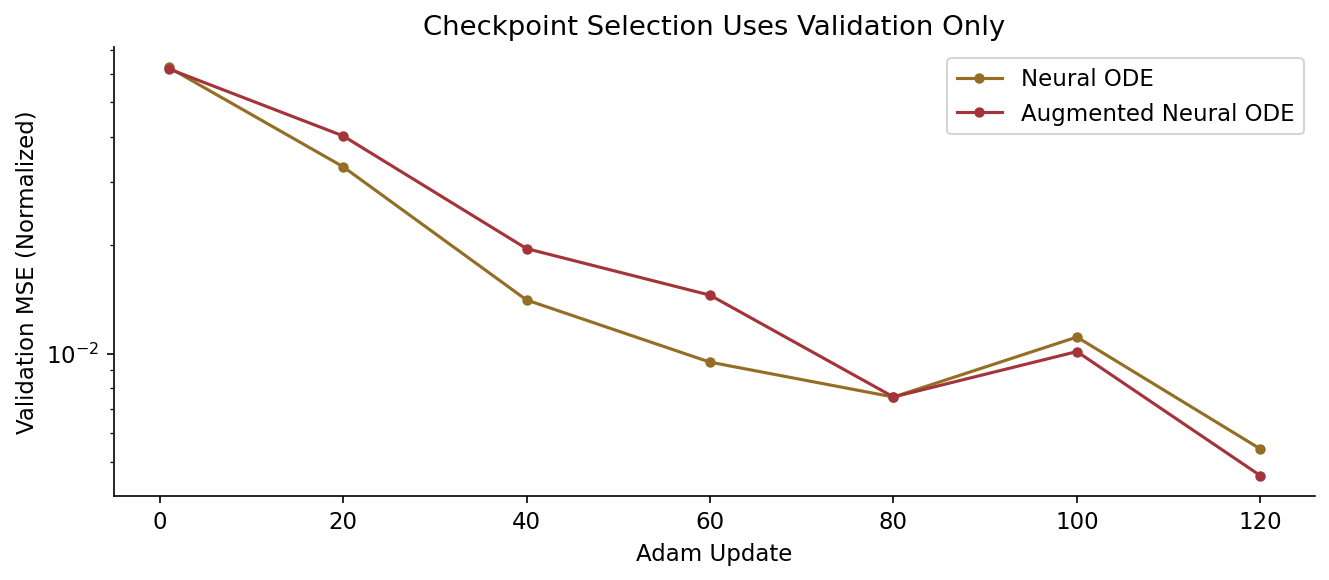

| Model | Selected update | Neural parameters |
| --- | --- | --- |
| Neural ODE | 120 | 370 |
| Augmented Neural ODE | 120 | 403 |

optimizer.zero_grad(set_to_none=True)
        prediction=odeint(model,state,times,method='rk4',options={'step_size':config['solver_step_samples']})[...,0]
        loss=(prediction-y[indices]).square().mean()
        if not torch.isfinite(loss):raise RuntimeError('Nonfinite training loss')
        loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),10.0);optimizer.step()

In [9]:
show('training_history.png')
table(['Model','Selected update','Neural parameters'],
      [(name,metrics['selected_updates'][name],metrics['parameter_counts'][name])
       for name in ['Neural ODE','Augmented Neural ODE']])
start=source.index('        optimizer.zero_grad')
end=source.index("        if update==1",start)
display(Code(source[start:end],language='python'))

## 7. Solver Cost and Numerical Resolution

The RK4 step is half a sample interval, about 0.819 ms. The check halves it again
while keeping fitted weights and the input interpolation rule fixed. The maximum
output change measures sensitivity to the numerical step, not error against an
unknown exact continuous trajectory.

A smaller step costs more evaluations. Stiff dynamics can raise solver cost
further, but this dataset run does not establish that stiffness caused the earlier
20-minute hang.


Validation maximum step-halving change: 0.2984 mV
Test maximum step-halving change: 0.3429 mV
Worker runtime: 48.24 s
Scientific versions: {'python': '3.12.14', 'torch': '2.8.0+cpu', 'numpy': '2.3.5', 'scipy': '1.17.0', 'torchdiffeq': '0.2.5', 'matplotlib': '3.10.8'}


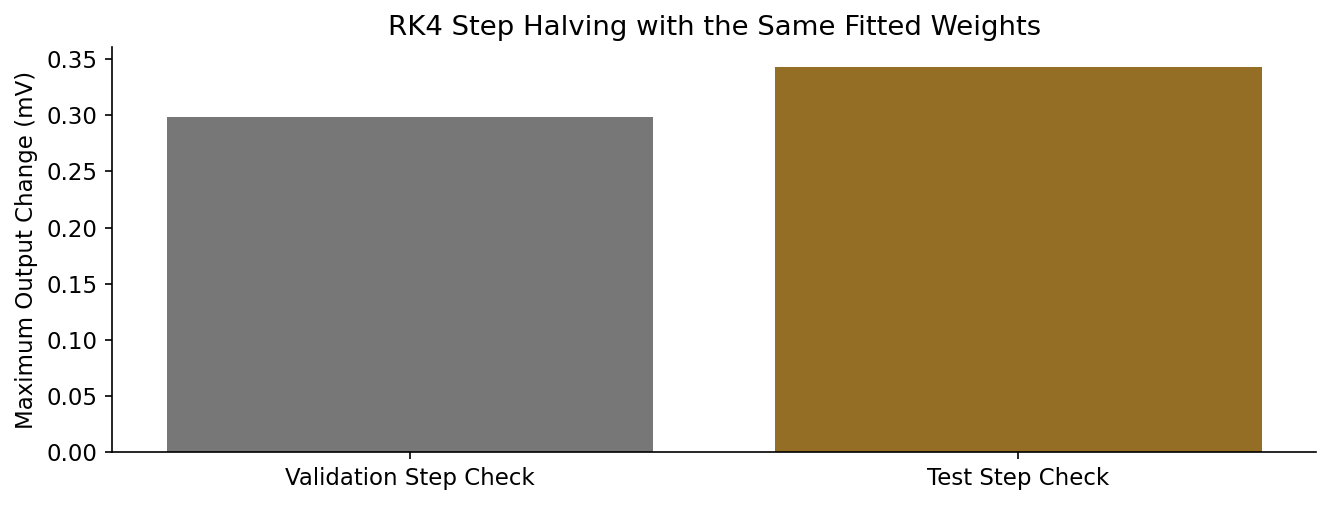

In [10]:
show('step_check.png')
print('Validation maximum step-halving change:',round(metrics['validation_step_halving_max_change_mV'],4),'mV')
print('Test maximum step-halving change:',round(metrics['step_halving_max_change_mV'],4),'mV')
print('Worker runtime:',round(metrics['elapsed_seconds'],2),'s')
print('Scientific versions:',metrics['versions'])

## 8. Full State and Augmentation

The ordinary model uses two latent coordinates. The augmented model appends one
coordinate initialized at zero and learns its dynamics together with the others.
The measured output remains a projection onto the first coordinate.

$$z_{0,\mathrm{aug}}=[\widetilde y_{49},\widetilde y_{48},0]^\top.$$

This implements the added-coordinate idea in Dupont et al. It does not reproduce
their image-classification experiment. Different full states can have the same
measured voltage. Full-state ODE uniqueness therefore does not imply that voltage
alone forms a complete dynamical state. An improvement in one seeded run is not
a general guarantee that augmentation helps.


Observed test RMSE reduction with augmentation: 22.28 %
This is one seed and a small classroom subset.


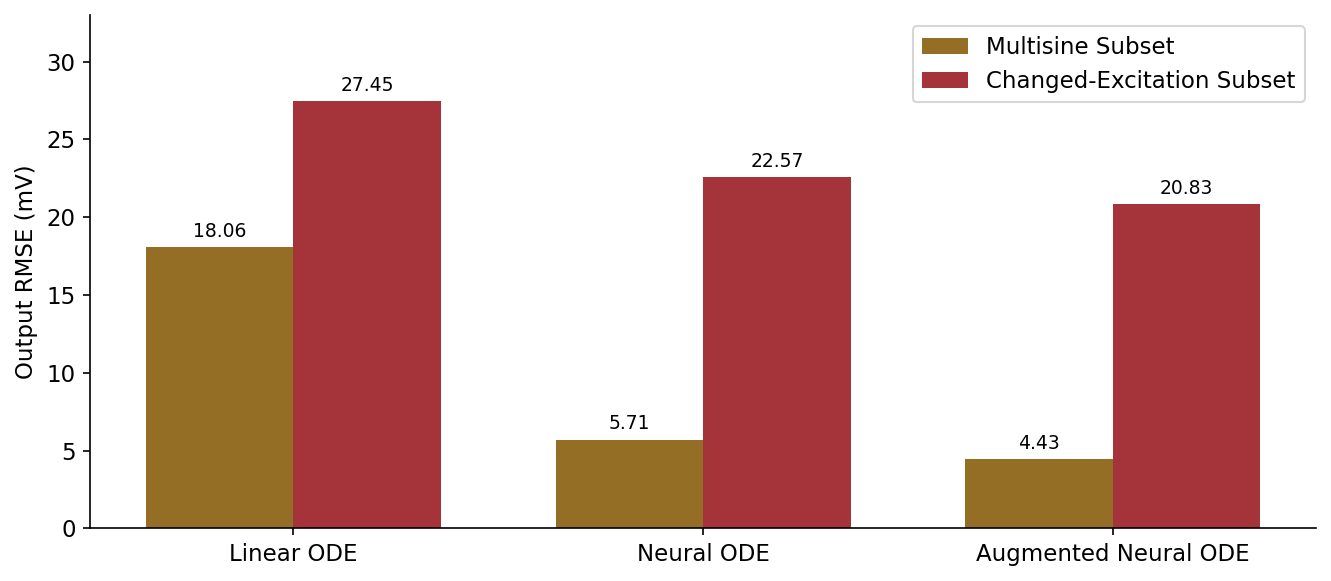

In [11]:
show('augmentation.png')
base=metrics['scores']['Neural ODE']['test']['rmse_mV']
aug=metrics['scores']['Augmented Neural ODE']['test']['rmse_mV']
print('Observed test RMSE reduction with augmentation:',round(100*(1-aug/base),2),'%')
print('This is one seed and a small classroom subset.')

## 9. Paper Links, File Alignment, and Reproducibility

- **Chen et al. (2018):** the network supplies an ODE right-hand side and training
  differentiates a trajectory loss. Their latent-ODE discussion motivates a state
  representation when observations are incomplete. This deterministic initializer
  differs from their variational latent model.
- **Dupont et al. (2019):** the augmented comparison adds a zero-initialized state
  coordinate, integrates it jointly, and projects to the measured output.
- The presentation's demo tables and chart series come from the packaged
  `results/metrics.json` and `results/*_predictions.csv` produced by this code.
- `reproducibility_report.json` records two fresh-process reruns. CSV input hashes,
  code and configuration hashes, selected checkpoints, and numeric prediction
  agreement establish which run the slides use.
- Packaged data allow offline execution. `fetch_data.py` can recreate the CSVs
  from the original public archive when internet access is available.

The plotting convention compares measurements with simulated outputs and then
shows their residuals. This follows standard system-identification practice:
MathWorks `compare` documents overlaid outputs and an error-plot option;
Schoukens, *Improved Initialization of State-Space Artificial Neural Networks*,
ECC, equations (6) and (8), defines simulation-error training and test RMSE, and
Figure 5 displays output and residuals. These sources justify the evaluation
method. Our numeric results come from this code and the measured classroom
subsets, rather than from those publications.


In [12]:
assert metrics['code_sha256']==digest(ROOT/'silverbox_demo.py'), 'Result/code mismatch'
assert metrics['config']==CONFIG, 'Result/configuration mismatch'
assert metrics['data_sha256']=={k:v['sha256']for k,v in manifest['classroom_subsets'].items()}
columns={'Linear ODE':'linear_ode_V','Neural ODE':'neural_ode_V','Augmented Neural ODE':'augmented_neural_ode_V'}
for split in ['test','high_amplitude']:
    with (active_results/f'{split}_predictions.csv').open(newline='')as stream:
        values=list(csv.DictReader(stream))[1:]
    assert len(values)==metrics['scored_samples_per_record']
    for name,column in columns.items():
        rmse=1000*math.sqrt(sum((float(row[column])-float(row['measured_output_V']))**2 for row in values)/len(values))
        assert math.isclose(rmse,metrics['scores'][name][split]['rmse_mV'],rel_tol=1e-10)
print('Verified: data hashes, code hash, configuration, scoring counts, and CSV-derived RMSE.')
report=ROOT/'reproducibility_report.json'
if report.exists():
    verification=json.loads(report.read_text())
    print('Packaged rerun verification:',verification['status'])
    print('Prediction CSV files identical:',verification['prediction_csv_identical'])

Verified: data hashes, code hash, configuration, scoring counts, and CSV-derived RMSE.
Packaged rerun verification: passed
Prediction CSV files identical: True


## Conclusions

- A Neural ODE learns a continuous dynamic surrogate from measured trajectories.
- This demo fits an input-driven voltage response with an unobserved internal state.
- Validation selects checkpoints, and an independent clip tests forecasting.
- Augmentation changes the representation; numerical resolution changes integration.
- The clip with changed input amplitude and waveform has larger errors in this run.
- These classroom results do not establish performance on the full Silverbox test.

**References**

1. Chen et al., *Neural Ordinary Differential Equations* (2018): https://arxiv.org/abs/1806.07366
2. Dupont et al., *Augmented Neural ODEs* (2019): https://arxiv.org/abs/1904.01681
3. Wigren and Schoukens, *Three Free Data Sets for Development and Benchmarking in Nonlinear System Identification* (2013), DOI: 10.23919/ECC.2013.6669201.
4. Dataset and protocol: https://www.nonlinearbenchmark.org/benchmarks/silverbox
5. Solver: https://github.com/rtqichen/torchdiffeq

6. MathWorks, *Compare Identified Model Output with Measured Output*:
   https://www.mathworks.com/help/ident/ref/compare.html
7. Schoukens, *Improved Initialization of State-Space Artificial Neural Networks*,
   ECC, DOI: 10.23919/ECC54610.2021.9655207. Author manuscript:
   https://arxiv.org/abs/2103.14516


In [13]:
print('NOTEBOOK COMPLETE:',NOTEBOOK_REVISION)
print('Result mode:',result_source)
print('Result directory:',active_results)

NOTEBOOK COMPLETE: R5-2026-10-15-Silverbox-Residuals
Result mode: LIVE RESULTS: fresh training in the current environment
Result directory: /workspace/scratch/acf5d2f58510/second_pass/results/live
